## Loading Libraries

In [1]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
import keras
from keras.preprocessing import sequence
from keras.callbacks import ModelCheckpoint,ReduceLROnPlateau,EarlyStopping

### Loading dataset

In [2]:
path_to_file = tf.keras.utils.get_file('shakespeare.txt', 'https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt')


1130496/1115394 [==============================] - 0s 0us/step


In [3]:
text = open(path_to_file, 'rb').read().decode(encoding='utf-8')
# length of text is the number of characters in it
print ('Length of text: {} characters'.format(len(text)))

Length of text: 1115394 characters


### Creating vocabulary and converting char to text and text to char

In [4]:
vocab = sorted(set(text))
char2idx = {u:i for i,u in enumerate(vocab)}
idx2char = np.array(vocab)

def text_to_int(text):
  return np.array([char2idx[c] for c in text])

text_as_int = text_to_int(text)

In [5]:
print("Text: ",text[:13])
print("Encoded: ",text_to_int(text[:13]))

Text:  First Citizen
Encoded:  [18 47 56 57 58  1 15 47 58 47 64 43 52]


In [6]:
def int_to_text(ints):
  try:
    ints = ints.numpy()
  except:
    pass
  return ''.join(idx2char[ints])

print(int_to_text(text_as_int[:13]))

First Citizen


### Creating training examples

In [7]:
seq_length = 100
epochs = len(text)//(seq_length+1)

char_dataset = tf.data.Dataset.from_tensor_slices(text_as_int)

2022-03-21 12:36:29.125123: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:937] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2022-03-21 12:36:29.211598: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:937] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2022-03-21 12:36:29.212320: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:937] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2022-03-21 12:36:29.215323: I tensorflow/core/platform/cpu_feature_guard.cc:142] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compil

In [8]:
seq = char_dataset.batch(seq_length+1 , drop_remainder = True)


In [9]:
def split_input_target(chunk):
  input_text = chunk[:-1]
  target_text = chunk[1:]
  return input_text,target_text

dataset = seq.map(split_input_target  )

### Printing the text

In [10]:
for x,y in dataset.take(2):
  print("\n\nExample\n")
  print("Input")
  print(int_to_text(x))
  print("\nOutput")
  print(int_to_text(y))



Example

Input
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You

Output
irst Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You 


Example

Input
are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you 

Output
re all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you k


2022-03-21 12:36:31.698199: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:185] None of the MLIR Optimization Passes are enabled (registered 2)


### Batch training

In [11]:
BATCH_SIZE = 64
VOCAB_SIZE = len(vocab)
EMBEDDING_DIM = 256
RNN_UNITS = 1024

BUFFER_SIZE = 1000
data = dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE,drop_remainder = True)

### Model


In [12]:
def build_model(vocab_size, embedding_dim,rnn_units,batch_size):
  model = tf.keras.Sequential([
                               tf.keras.layers.Embedding(vocab_size,embedding_dim,batch_input_shape = [batch_size,None]),
                               tf.keras.layers.LSTM(rnn_units, return_sequences = True, stateful = True, recurrent_initializer = 'glorot_uniform'),
                               tf.keras.layers.Dense(vocab_size)

  ])
  return model
model = build_model(VOCAB_SIZE,EMBEDDING_DIM,RNN_UNITS,BATCH_SIZE)
model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding (Embedding)        (64, None, 256)           16640     
_________________________________________________________________
lstm (LSTM)                  (64, None, 1024)          5246976   
_________________________________________________________________
dense (Dense)                (64, None, 65)            66625     
Total params: 5,330,241
Trainable params: 5,330,241
Non-trainable params: 0
_________________________________________________________________


### Loss function

In [13]:
for input_example_batch,target_example_batch in data.take(1):
  example_batch_predictions = model(input_example_batch)
  print(example_batch_predictions.shape)

2022-03-21 12:36:32.958287: I tensorflow/stream_executor/cuda/cuda_dnn.cc:369] Loaded cuDNN version 8005


(64, 100, 65)


In [14]:
print(len(example_batch_predictions))
print(example_batch_predictions)

64
tf.Tensor(
[[[-6.05337322e-03  6.06625900e-03 -1.69885898e-05 ... -2.28285021e-03
   -4.21570567e-03 -2.66753044e-03]
  [-5.23816422e-03  4.61793691e-03 -1.17608290e-02 ... -1.44323579e-03
   -1.82086905e-03  9.46905231e-04]
  [-9.87576228e-03  9.61039402e-03 -9.28576291e-03 ... -3.22117563e-03
   -4.76195756e-03 -1.42869446e-03]
  ...
  [-7.27287587e-03  3.84986866e-03 -1.83184128e-02 ... -1.59163109e-03
    3.25189671e-03 -7.54578412e-03]
  [-5.92862722e-03  1.10684661e-03 -1.84623897e-02 ...  7.60537223e-04
   -2.37168511e-04 -7.05897668e-03]
  [-4.47580125e-03 -3.21667467e-04 -8.28207284e-03 ... -8.99060629e-04
    5.49715571e-03 -2.65536201e-03]]

 [[-1.52882468e-03 -6.09554874e-04 -1.14973858e-02 ...  2.86858471e-04
    1.18946086e-03  2.47103651e-03]
  [-2.78395624e-03 -3.76937678e-04 -8.24265555e-03 ... -3.45862075e-03
    1.61510019e-03 -6.04799949e-03]
  [-2.18659267e-03 -5.66895003e-04 -1.05133206e-02 ... -3.46548320e-03
   -1.17268937e-03 -6.72304910e-03]
  ...
  [-8.872

In [15]:
pred = example_batch_predictions[0]
print(len(pred))
print(pred)

100
tf.Tensor(
[[-6.0533732e-03  6.0662590e-03 -1.6988590e-05 ... -2.2828502e-03
  -4.2157057e-03 -2.6675304e-03]
 [-5.2381642e-03  4.6179369e-03 -1.1760829e-02 ... -1.4432358e-03
  -1.8208690e-03  9.4690523e-04]
 [-9.8757623e-03  9.6103940e-03 -9.2857629e-03 ... -3.2211756e-03
  -4.7619576e-03 -1.4286945e-03]
 ...
 [-7.2728759e-03  3.8498687e-03 -1.8318413e-02 ... -1.5916311e-03
   3.2518967e-03 -7.5457841e-03]
 [-5.9286272e-03  1.1068466e-03 -1.8462390e-02 ...  7.6053722e-04
  -2.3716851e-04 -7.0589767e-03]
 [-4.4758013e-03 -3.2166747e-04 -8.2820728e-03 ... -8.9906063e-04
   5.4971557e-03 -2.6553620e-03]], shape=(100, 65), dtype=float32)


In [16]:
time_pred = pred[0]
print(len(time_pred))
print(time_pred)


65
tf.Tensor(
[-6.0533732e-03  6.0662590e-03 -1.6988590e-05 -4.6567025e-04
 -5.0640185e-03 -8.2127303e-03 -4.8505026e-04 -1.3435832e-03
  5.3496808e-03  1.8426554e-03 -1.0210044e-03 -2.3347288e-03
  1.0121699e-03  7.0214849e-03  1.5197438e-05  1.1496756e-03
  5.3773588e-03 -3.4622804e-03 -1.4127383e-03 -2.5830460e-03
 -4.6662916e-04 -4.2427666e-03  7.2445106e-03 -4.0093604e-03
  2.7526047e-03 -1.0857212e-03 -4.6243672e-03 -6.8200962e-04
  1.2732418e-03 -3.6708547e-03  8.6831010e-04 -7.5767632e-05
 -1.7732610e-03  4.1059754e-04  1.6342072e-03 -1.7973820e-03
  2.4138936e-03 -2.8343864e-03  1.7433002e-03  1.8572274e-03
  4.9016112e-03 -3.3892305e-03  1.1348494e-03 -7.8401470e-04
 -6.6295392e-03 -5.6314887e-04 -3.1256292e-03 -4.5251031e-04
 -3.8937535e-03 -7.9109240e-04  9.9687628e-04 -3.2813959e-03
  8.0943219e-03  2.0723217e-03  3.1089475e-03 -2.3531434e-03
 -2.6628356e-03  4.2445278e-03 -3.0891844e-03  2.5795060e-03
  3.4656376e-04  1.5732367e-04 -2.2828502e-03 -4.2157057e-03
 -2.667530

In [17]:
sampled_indices = tf.random.categorical(pred, num_samples = 1)
sampled_indices = np.reshape(sampled_indices, (1,-1))[0]
predicted_chars = int_to_text(sampled_indices)

predicted_chars

"PmHlfoCto-a?'OyOH-GHbYKlJp'AZBobk.h.&&o!Bre3oIjONyefq?x'uGkN&.grN$wA:nf$ TXNBDi,rE.ntkR$YRPij$N;vszw"

In [18]:
def loss(labels,logits):
  return tf.keras.losses.sparse_categorical_crossentropy(labels,logits,from_logits= True)  

In [19]:
model.compile(optimizer = 'adam', loss = loss, metrics = ['accuracy'])


### Early stop , Checkpoint and LRonPlateau

In [20]:
filepath = '/content/sample_data/lstm.h5'
checkpoint = ModelCheckpoint(filepath,monitor = 'loss', verbose = 1, save_best_only = True, mode = 'min')
early_stop=EarlyStopping(monitor='loss',mode='min',verbose=1,patience=5)
lr_reduce = ReduceLROnPlateau(monitor='accuracy', factor=0.6,patience=5, verbose=1, mode='max', min_lr=0.001)
callbacklist = [lr_reduce,checkpoint,early_stop]


### Fitting the model

In [21]:
history = model.fit(data, epochs = 100, callbacks = callbacklist)


Epoch 1/100
172/172 [==============================] - 12s 60ms/step - loss: 2.5869 - accuracy: 0.2910

Epoch 00001: loss improved from inf to 2.58688, saving model to /content/sample_data/lstm.h5
Epoch 2/100
172/172 [==============================] - 11s 61ms/step - loss: 1.9104 - accuracy: 0.4424

Epoch 00002: loss improved from 2.58688 to 1.91041, saving model to /content/sample_data/lstm.h5
Epoch 3/100
172/172 [==============================] - 10s 60ms/step - loss: 1.6718 - accuracy: 0.5063

Epoch 00003: loss improved from 1.91041 to 1.67183, saving model to /content/sample_data/lstm.h5
Epoch 4/100
172/172 [==============================] - 10s 60ms/step - loss: 1.5318 - accuracy: 0.5428

Epoch 00004: loss improved from 1.67183 to 1.53177, saving model to /content/sample_data/lstm.h5
Epoch 5/100
172/172 [==============================] - 10s 60ms/step - loss: 1.4459 - accuracy: 0.5649

Epoch 00005: loss improved from 1.53177 to 1.44594, saving model to /content/sample_data/lstm.h5

#### The model ran for 95 epochs in my case as the loss did not decrease it stops

### Building the model for generating text

In [22]:
model = build_model(VOCAB_SIZE, EMBEDDING_DIM, RNN_UNITS, batch_size = 1)


In [23]:
model.load_weights(filepath)
model.build(tf.TensorShape([1,None]))


### Generate text

In [24]:
def generate_text(model, start_string):
  num_generate = 800
  input_eval = [char2idx[s] for s in start_string]
  input_eval = tf.expand_dims(input_eval,0)

  text_generated = []

  temp= 1.0

  model.reset_states()
  for i in range(num_generate):
    predictions = model(input_eval)
    predictions = tf.squeeze(predictions,0)
    predictions = predictions/temp
    predicted_id = tf.random.categorical(predictions, num_samples = 1)[-1,0].numpy()
    input_eval = tf.expand_dims([predicted_id], 0)
    text_generated.append(idx2char[predicted_id])

  return(start_string + ''.join(text_generated))

In [25]:
inp = input('Type a starting string: ')
print(generate_text(model,inp))

Type a starting string:  romeo


romeough the princes have betured to do so.

Provost:
In good times strings before a usurer; it is done,
And then, to purge full of itself, but with the
intedious faults, and is not Half-can tyranny:
To make a pelibate and goodness on thee,
Being crown'd the age us to incur you come; for then I play thee go, a
matter and a coward, a tell thou art.

GLOUCESTER:
But shall I live on nature, of a sister God presently
Hath your employment in my way,
Knowing a tardy world, an humbly thanks.

GLOUCESTER:
Ah! at once we stop all her beseeching greater them.

BIANCA:
The two right suprements my son should be
The freshest things now of the midnight
Shall have a high and supper in Baptista.

BAPTISTA:
Good my lord, good night: I know it please you did thream.

HORTENSIO:
I am content.

MARCIUS:
Well, sir,


## Plotting the graphs

In [26]:
import matplotlib.pyplot as plt


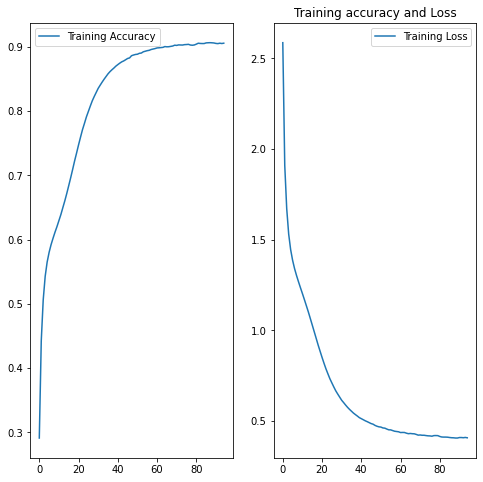

In [30]:
acc = history.history['accuracy']

loss = history.history['loss']

epochs_range = range(95)
plt.figure(figsize=(8, 8))
plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.legend(loc='best')
plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label='Training Loss')

plt.title('Training and Validation Accuracy')
plt.legend(loc='best')

plt.title('Training accuracy and Loss')
plt.show()